OBJETIVO

Sua missão é avaliar os dados e responder a 10 perguntas levantadas pela equipe de
marketing, que estão listadas abaixo

IMPORTANDO AS BIBLIOTECAS NECESSÁRIAS PARA A ANÁLISE DOS DADOS:

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

IMPORTANDO A BASE DE DADOS:

In [8]:
#importando dataframe

df= pd.read_csv("vendas_supermercado_com_cliente.csv")

CONHECENDO A BASE DE DADOS:

In [8]:
# checando qtde de linhas e colunas do df

df.shape

# 20075 linhas (contando com a linha que consta os nomes das colunas) e 9 colunas

(20075, 9)

In [9]:
#lendo as primeiras 15 linhas do df

df.head(15)

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
0,2023-01-01,Maçãs,Alimentos Frescos,16.46,10,0.0,164.60,49,2715.61
1,2023-01-01,Bananas,Alimentos Frescos,2.39,4,0.0,9.56,29,2280.15
2,2023-01-01,Laranjas,Alimentos Frescos,8.38,5,0.0,41.90,67,4419.56
3,2023-01-01,Tomates,Alimentos Frescos,2.03,15,0.0,30.45,29,3809.17
4,2023-01-01,Alface,Alimentos Frescos,37.14,14,0.0,519.96,24,1013.42
5,2023-01-01,Cenouras,Alimentos Frescos,17.52,4,0.0,70.08,37,4959.66
6,2023-01-01,Frango,Alimentos Frescos,38.17,3,0.0,114.51,63,2033.87
7,2023-01-01,Carne bovina,Alimentos Frescos,22.07,16,0.0,353.12,32,2682.55
8,2023-01-01,Carne suína,Alimentos Frescos,17.66,9,0.0,158.94,39,1854.33
9,2023-01-01,Salmão,Alimentos Frescos,6.66,2,0.0,13.32,67,1686.49


In [10]:
#lendo as 15 ultimas linhas do df

df.tail(15)

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
20060,2023-12-31,Papel higiênico,Produtos de Higiene Pessoal,9.81,11,0.18,88.4862,35,4239.52
20061,2023-12-31,Sorvetes,Congelados,5.44,7,0.23,29.3216,35,1416.45
20062,2023-12-31,Pizzas congeladas,Congelados,2.35,7,0.27,12.0085,20,1079.86
20063,2023-12-31,Vegetais congelados,Congelados,48.79,1,0.12,42.9352,60,1742.69
20064,2023-12-31,Pratos prontos congelados,Congelados,46.23,3,0.17,115.1127,50,1526.18
20065,2023-12-31,Frango empanado,Congelados,4.11,16,0.15,55.8960,22,4272.07
20066,2023-12-31,Ração para cães,Pet Shop,45.21,8,0.16,303.8112,31,4249.12
20067,2023-12-31,Ração para gatos,Pet Shop,31.53,14,0.26,326.6508,20,2676.65
20068,2023-12-31,Petiscos,Pet Shop,37.59,14,0.22,410.4828,74,3827.82
20069,2023-12-31,Brinquedos para pets,Pet Shop,10.58,18,0.13,165.6828,56,1241.06


ANALISANDO A BASE DE DADOS:

In [11]:
# checando informações gerais sobre o df
# qtde de nulos, tipos de dados, uso de memória

df.info()

# >> não apresentou linhas com dados nulos, pois todas as colunas apresentam as 20075 linhas não nulas


<class 'pandas.DataFrame'>
RangeIndex: 20075 entries, 0 to 20074
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Data         20075 non-null  str    
 1   Produto      20075 non-null  str    
 2   Categoria    20075 non-null  str    
 3   Preço        20075 non-null  float64
 4   Quantidade   20075 non-null  int64  
 5   Desconto     20075 non-null  float64
 6   Total_Venda  20075 non-null  float64
 7   Idade        20075 non-null  int64  
 8   Renda        20075 non-null  float64
dtypes: float64(4), int64(2), str(3)
memory usage: 1.4 MB


In [12]:
# aprofundando a checagem de dados nulos

df.isnull().sum()

# >> reforçado que as colunas não apresentam dados nulos

Data           0
Produto        0
Categoria      0
Preço          0
Quantidade     0
Desconto       0
Total_Venda    0
Idade          0
Renda          0
dtype: int64

In [13]:
# checando descritivamente todas as colunas do df (numéricas e categóricas) 

df.describe(include="all").round(1)

# count - todas as 9 colunas apresentam todas as 20075 linhas estão preenchidas, então não possui 
# dados nulos ou ausentes

# unique - qtde de  valores únicos em cada um das colunas. Na coluna "Data", por exemplo, consta que o DF possui 365
# registros únicos, ou seja, 1 ano inteiro de registros.

# top - apresenta valor frequente em cada coluna (moda)

# freq - apresente qtas vezes um dado se repete

# >> a data de '2023-01-01' aparece 55 vezes, sendo o produto "Maçãs" apresentando 365 vezes, possivelmente 
# aparecendo nos registros diariamente e "Alimentos Frescos" aparece 5475 vezes, representa uma parte grande do 
# volume de dados num todo

# mean - média de cada coluna numérica, chamando a atenção para a média de  "Desconto" zerada (grande parte das 
# vendas sem desconto)

# std - desvio padrão(dispersão) dos dados em relação à média

# min / max - menor e maior valor, respectivamente, em cada coluna

# >> variação do 'Preço' (1 a 50) representa uma dispersão significativa (desvio padrão de 14), "Quantidade"
# com variação menor (1 a 19 - desvio padrão de 5,5), "Desconto" com variação baixíssima e desvio quase nulo(0,1) e 
# "Total_Vendas" com dispersão gigantesca(0,9 a 949 com desvio padrão alto 207,8)

# 25%, 50%, 75% - quartis de cada coluna

# >> checando os quartis, a mediana (25,6) é próxima da média (25,7), representando pouquíssima variação entre o "Preço"
# dos produtos. 
# Consta certo equilíbrio entre a "Quantidade" de protudo (5 - 25%, 10 - 50% e 15 - 75%). A mediana 
# (50%) do "Total_Vendas" é de 186,3, menor que a média (245,9), ou seja, a maioria das vendas faturam baixo
# com algumas de valores elevados, que puxam a média para cima.

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
count,20075,20075,20075,20075.0,20075.0,20075.0,20075.0,20075.0,20075.0
unique,365,55,9,NaN,NaN,NaN,NaN,NaN,NaN
top,2023-01-01,Maçãs,Alimentos Frescos,NaN,NaN,NaN,NaN,NaN,NaN
freq,55,365,5475,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,25.6,10.0,0.0,245.9,46.0,2999.0
std,NaN,NaN,NaN,14.1,5.5,0.1,207.8,16.5,1159.7
min,NaN,NaN,NaN,1.0,1.0,0.0,0.9,18.0,1000.4
25%,NaN,NaN,NaN,13.3,5.0,0.0,75.6,32.0,1993.6
50%,NaN,NaN,NaN,25.7,10.0,0.0,186.3,46.0,2998.8
75%,NaN,NaN,NaN,37.8,15.0,0.0,370.0,60.0,4007.7


<Axes: xlabel='Total_Venda'>

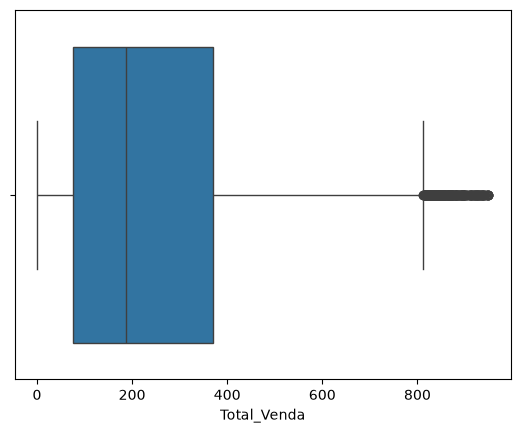

In [14]:
# gráfico para demonstração dos quartis da coluna "Total_Venda", para reafirmar análise descrita no 
# comando anteriormente

sns.boxplot(x=df['Total_Venda'])

In [31]:
# checando duplicidade de linhas no DF

df.duplicated()

# >> análise retorna resposta em booleano
# "False" >>  não detectou linhas duplicadas

0        False
1        False
2        False
3        False
4        False
         ...  
20070    False
20071    False
20072    False
20073    False
20074    False
Length: 20075, dtype: bool

In [32]:
#checando duplicidade de linhas nos DF

df.duplicated().sum()

# >> '0' > não apresenta dados duplicados

np.int64(0)

In [33]:
# demonstra as linhas duplicadas

df[df.duplicated()]

# >> como não tem linhas duplicadas, retornou vazio, como esperado!

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda


In [35]:
# demonstra as linhas NÃO duplicadas

df[~df.duplicated()]

#>> retornou todas as 20075 linhas do DF, como esperado!

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
0,2023-01-01,Maçãs,Alimentos Frescos,16.46,10,0.00,164.6000,49,2715.61
1,2023-01-01,Bananas,Alimentos Frescos,2.39,4,0.00,9.5600,29,2280.15
2,2023-01-01,Laranjas,Alimentos Frescos,8.38,5,0.00,41.9000,67,4419.56
3,2023-01-01,Tomates,Alimentos Frescos,2.03,15,0.00,30.4500,29,3809.17
4,2023-01-01,Alface,Alimentos Frescos,37.14,14,0.00,519.9600,24,1013.42
...,...,...,...,...,...,...,...,...,...
20070,2023-12-31,Produtos de higiene para pets,Pet Shop,26.62,15,0.21,315.4470,39,2475.82
20071,2023-12-31,Panelas,Utilidades Domésticas,33.00,19,0.15,532.9500,25,4766.49
20072,2023-12-31,Talheres,Utilidades Domésticas,27.60,12,0.29,235.1520,65,3367.68
20073,2023-12-31,Copos,Utilidades Domésticas,15.35,13,0.25,149.6625,42,3823.50


RESPONDENDO ÀS QUESTÕES:

1. Quais foram as categorias produtos mais vendidos e em quais meses eles tiveram o
maior pico de vendas?


In [9]:
#separando a data para considerar apenas o mês
df['Mes']=pd.to_datetime(df['Data']).dt.to_period('M') 
#pandas.to_datetime ( arg , errors = 'raise' , dayfirst = False , yearfirst = False , utc = False , 
#format = None , exact = <no_default> , unit = None , origin = ' unix' , cache = True )
#Converter argumento para data e hora.
#Esta função converte um valor escalar, semelhante a um array Series ou DataFrame semelhante a um 
#dicionário em um objeto datetime do pandas.

#DataFrame.to_period ( freq = None , axis = 0 , copy = <no_default> )​
#Converter DataFrame de DatetimeIndex para PeriodIndex.
#Converta um DataFrame de DatetimeIndex para PeriodIndex com a frequência desejada 
#(inferida a partir do índice, caso não seja especificado). Qualquer índice das colunas pode ser 
#convertido, dependendo do argumento do eixo.

#calculando a categoria mais vendida e mês de maior venda
Pico_Vendas=(df.groupby(['Categoria', 'Mes'])['Total_Venda']
            .sum()
            .reset_index()
            .sort_values(by='Total_Venda', ascending=False)
            .drop_duplicates(subset=['Categoria'])
            ).round({"Total_Venda": 2})
Pico_Vendas
#DataFrame.reset_index ( level = None , * , drop = False , inplace = <no_default> , col_level = 0 , 
#col_fill = ' ' , allow_duplicates = False , names = None )
#Redefina o índice, ou um de seus níveis.
#Redefine o índice do DataFrame e utiliza o índice padrão. Se o DataFrame possuir um MultiIndex, 
#este método pode remover um ou mais níveis.

#DataFrame.drop_duplicates ( subset = None , * , keep = ' first ' , inplace = False , 
#ignore_index = False )
#Retorna um DataFrame com as linhas duplicadas removidas.
#Considerar certas colunas é opcional. Os índices, incluindo os índices temporais, são ignorados.


#####ANALISE
# O 1º colocado 'Alimentos Frescos' representa 27,44% do volume total vendido, evidenciando que essa categoria é a 
# principal fonte de faturamento desse supermercado, ocorrendo o ápice das vendas no mês de março, que acredito ser 
# devido ao retorno das férias e retorno definitivo às aulas, onde as pessoas tem gasto maior para reposição de 
# produtos pela volta à rotina diária e por ser, acredito eu, período de grande produção (agro) de hortaliças, 
# frutas, verduras e afins.

# Seguido por "Produtos de Mercearia" que representa 10,24% do volume vendido, com maior venda em Setembro(que 
# não tenho idéia do porquê!!!! rsrs)

# Em janeiro temos "Bebidas" (10,08% do volume de vendas) como principal produto devido ao período de ano novo/férias 
# e "Pet Shop" (8,63% do volume de vendas) acredito que seja devido ao período de férias dos donos que aproveitam para 
# viajar, tendo que comprar produtos para hospedagem dos pets ou até mesmo renovar os produtos usados pelos pets 
# (camas, mantas, roupas, acessórios, etc). 

# Em outubro temos 'Laticínios e Ovos' (9,23% do volume total de vendas) e 'Congelados' (8,59% do volume total de vendas). 
# "Laticínios e Ovos" acredito também ter relação com a produção desses produtos (agro) nesse período. "Congelados" devido 
# à estação do ano onde aumenta o consumo de sorvetes, sobremesas geladas, sucos naturais e afins; e ainda, início das 
# vendas/estoques de produtos para as festas de fim de ano (aves, suinos e peixes congelados, por exemplo).

# E por fim, em julho foi ápice das vendas de "Produtos de Limpeza" (9% do volume de vendas), 'Produtos de Higiene Pessoal' 
# (8,97% do volume total de vendas) e 'Utilidades Dométicas' (último colocado com 7,80% do volume total de vendas ) que 
# acredito ser devido ao período de férias, crianças em casa, perído de chuvas, onde  os cuidados a casa  aumentam e devido 
# ao inverno, há um aumento em cuidados pessoais (como hidratantes, oléos corporais, etc).


,Categoria,Mes,Total_Venda
2,Alimentos Frescos,2023-03,129103.45
92,Produtos de Mercearia,2023-09,48192.29
12,Bebidas,2023-01,47415.71
45,Laticínios e Ovos,2023-10,43440.80
78,Produtos de Limpeza,2023-07,42358.75
66,Produtos de Higiene Pessoal,2023-07,42213.35
48,Pet Shop,2023-01,40577.29
33,Congelados,2023-10,40418.34
102,Utilidades Domésticas,2023-07,36674.81


2. Qual a média de vendas diárias por categoria de produto?


In [10]:
# calculando as vendas diárias de cada categoria
Vendas_Dia=df.groupby(['Categoria', 'Data'])['Total_Venda'].sum().reset_index()
#Vendas_Dia

# calculando a média diaria por categoria
Media_Diaria = (Vendas_Dia.groupby(['Categoria'])['Total_Venda'].mean()
                                                                .reset_index()
                                                                .rename(columns={'Total_Venda': 'Média Venda Diária'})
                                                                .sort_values(by='Média Venda Diária', ascending=False)
                                                                .round(2))
Media_Diaria
#DataFrame.rename ( mapper = None , '* ' , index = None , columns = None , axis = None , copy = <no_default> , 
#inplace = <no_default> , level = None , errors = 'ignore' )
#Renomeie colunas ou rótulos de índice.
#Os valores de função/dicionário devem ser únicos (um para um). Os rótulos que não estiverem contidos em um 
#dicionário/série permanecerão como estão. Rótulos extras listados não geram erro.

#####ANALISE
#Como esperado, 'Alimentos Frescos" possui maior média de venda diária(1/4 do faturamento diário), tendo mais do 
#dobro de média para o segundo colocado - 'Produtos de Mercearia'.
#As demais categorias tem média próxima (variação baixa entre elas).
#E em último temos a categoria 'Utilidades Domésticas" com a menor média diária, como esperado(conforme análise 
#anterior!)

,Categoria,Média Venda Diária
0,Alimentos Frescos,3740.57
7,Produtos de Mercearia,1451.11
3,Laticínios e Ovos,1260.17
1,Bebidas,1244.92
6,Produtos de Limpeza,1226.15
4,Pet Shop,1206.39
5,Produtos de Higiene Pessoal,1205.59
2,Congelados,1204.71
8,Utilidades Domésticas,984.99


3. Quais produtos apresentam a maior sazonalidade nas vendas (ex.: frutas e vegetais,
sorvetes)

In [11]:
#primeiro precisa somar as vendas totais dos produtos por mês para obter as vendas mensais por produto
#depois precisa calcular o desvio padrão dessas vendas mensais por produto para ter a 'sazonalidade'

df['Mes']=pd.to_datetime(df['Data']).dt.to_period('M')

sazonalidade=df.groupby(['Produto','Mes'])['Total_Venda'].sum().groupby('Produto').std().sort_values(ascending=False).round(2).reset_index(name="Sazonalidade")
sazonalidade

#####ANALISE
#pela resposta, 'Sucos' é o produto de maior sazonalidade, seguido de 'Atum', 'Tomates', 'Vinhos' e assim por diante...
#Não há grande diferença entre os produtos...os resultados são próximos, com exceção do 'Papel Higiênico' que possui
#a menor volatilidade
#Porém, devido às análises anteriores, 'Alimentos Frescos" sempre se sobresai, o que me deixou "encafifada"rs
#Por isso resolvi calcular o coeficiente de volatilidade que achei no google rs para tirar a prova....
#coeficiente de variação=desvio padrão/média

,Produto,Sazonalidade
0,Sucos,1751.82
1,Atum,1734.46
2,Tomates,1708.07
3,Vinhos,1689.40
4,"Produtos descartáveis (pratos, copos, talheres)",1662.65
5,Refrigerantes,1661.96
6,Croissants,1629.43
7,Alface,1575.42
8,Cervejas,1530.24
9,Carne bovina,1499.49


In [12]:
#calculando o coeficiente de volatilidade:
#coeficiente de variação=desvio padrão/média

df['Mes']=pd.to_datetime(df['Data']).dt.to_period('M')

venda_mensal=df.groupby(['Produto','Mes'])['Total_Venda'].sum()

sazonalidade=(venda_mensal.groupby('Produto').std()/venda_mensal.groupby('Produto').mean()).sort_values(ascending=False).round(2).reset_index(name="%Sazonalidade")
sazonalidade

#####ANALISE
#tirando a prova, realmente não há grande variação entre os produtos, 
#sendo os mais voláteis praticamente os menos da análise anterior:'Vinhos', 'Sucos', "Atum"(23%)
#a alteração está no produto 'Tomate' que era o 3º mais volátil na análise anterior e nesta é o 2º maior coeficiente com 22%
#e 'Produtos descartáveis' que nesta análise está no maior coeficiente (23%) sendo que na anterior era o 5º produto mais volátil...
#Nesta análise se reafirmou o 'Papel Higiênico" como o menos volatil(8%)...

,Produto,%Sazonalidade
0,"Produtos descartáveis (pratos, copos, talheres)",0.23
1,Vinhos,0.23
2,Sucos,0.23
3,Atum,0.23
4,Tomates,0.22
5,Refrigerantes,0.22
6,Croissants,0.22
7,Ração para gatos,0.21
8,Cervejas,0.20
9,Alface,0.20


4. Quais as faixas etárias contribuíram mais para as vendas totais? Para responder essa
pergunta, crie uma coluna com a faixa etária, considerando: entre 18 e 35 (jovem), entre
36 e 59 (adulto) e acima de 60 anos (idoso).


In [176]:
Jovem=df[(df['Idade']>=18)&(df['Idade']<=35)]['Total_Venda'].sum()

Adulto=df[(df['Idade']>=36)&(df['Idade']<=59)]['Total_Venda'].sum()

Idoso=df[df['Idade']>=60]['Total_Venda'].sum()

resultado=pd.DataFrame({
            'Faixa_etaria':['Jovem', 'Adulto', 'Idoso'],
            'Total_Venda':[Jovem, Adulto, Idoso]}).sort_values(by='Total_Venda', ascending=False).round(2)
resultado

#####ANALISE
#A faixa etária que mais contribui no total da vendas é a faixa Adulta com 36,75% a mais que os Jovens e 62,04% a mais 
#que os Idosos, diferença bastante relevante!!

,Faixa_etaria,Total_Venda
1,Adulto,2102041.77
0,Jovem,1537183.38
2,Idoso,1297252.20


<Axes: xlabel='Total_Venda', ylabel='Faixa_etaria'>

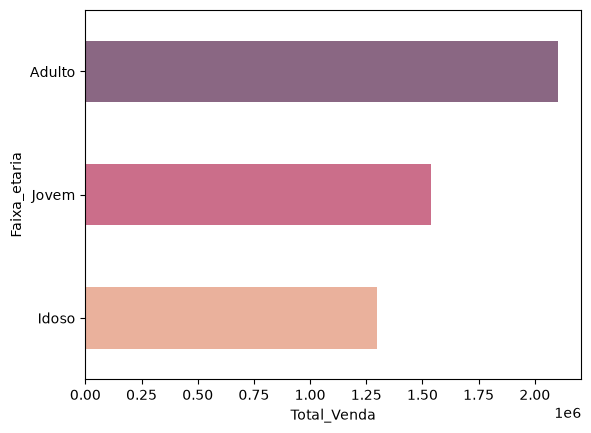

In [177]:
#demonstrando o resultado em gráfico

#seaborn.barplot ( data=None , * , x=None , y=None , hue =None , order=None , hue_order=None , 
# estimator='mean' , errorbar=('ci' , 95) , n_boot00=10 , seed=None , units=None , weights=None , 
# orient=None , color=None , palette=None , saturation=0.75 , fill=True , hue_norm=None , width=0.8 , 
# dodge='auto' , gap=0 , log_scale=None , native_scale=False , formatter=None , legend='auto' , capsize=0 , 
# err_kws=None , ci=<deprecated> , errcolor=<deprecated> , errwidth=<obsoleto> , ax=None , **kwargs )

#seaborn.objects.Bars 
#class seaborn.objects.Bars ( artist_kws =<factory> , color=<'C0'> , alpha=<0.7> , fill=<True> , 
# edgecolor=<rc:patch.edgecolor> , edgealpha=<1> , edgewidth=<auto> , edgestyle=<'-'> , width=<1> , baseline=<0> ) 

sns.barplot(data=resultado, x='Total_Venda', y="Faixa_etaria", 
            hue='Faixa_etaria', palette='rocket', legend=False, width=0.5, alpha=0.7, weights=0.5)


5. Qual é a relação entre a idade dos clientes e a categoria de produto mais vendida para
cada?

In [243]:
#pandas.cut ( x , bins , right = True , labels = None , retbins = False , precision = 3 , 
# include_lowest = False , duplicates = ' raise' , ordered = True )
#Agrupe os valores em intervalos discretos.
#Use a função `cut` quando precisar segmentar e classificar valores de dados em intervalos. 
# Essa função também é útil para converter uma variável contínua em uma variável categórica. 
# Por exemplo, `cut` pode converter idades em grupos de faixas etárias. Ela suporta a divisão 
# em um número igual de intervalos ou em uma matriz de intervalos predefinida.

#criando faixas etárias:
bins=[18, 34, 59, 100] # de 18 a 34(Jovem), de 35 a 59(Adulto), 60 a 100(Idoso)
labels=['Jovem', 'Adulto', 'Idoso']
df['Faixa_etaria']=pd.cut(df['Idade'], bins=bins, labels=labels)

idade_categoria=df.groupby(['Faixa_etaria', 'Categoria'])['Total_Venda'].sum().reset_index().round(2)
print(idade_categoria)




   Faixa_etaria                    Categoria  Total_Venda
0         Jovem            Alimentos Frescos    374199.85
1         Jovem                      Bebidas    126522.77
2         Jovem                   Congelados    119005.82
3         Jovem            Laticínios e Ovos    119162.88
4         Jovem                     Pet Shop    114872.26
5         Jovem  Produtos de Higiene Pessoal    128302.72
6         Jovem          Produtos de Limpeza    137067.87
7         Jovem        Produtos de Mercearia    151797.28
8         Jovem        Utilidades Domésticas     99699.40
9        Adulto            Alimentos Frescos    610240.44
10       Adulto                      Bebidas    190237.10
11       Adulto                   Congelados    197424.17
12       Adulto            Laticínios e Ovos    209278.38
13       Adulto                     Pet Shop    206850.69
14       Adulto  Produtos de Higiene Pessoal    196075.36
15       Adulto          Produtos de Limpeza    190718.66
16       Adult

<Axes: xlabel='Faixa_etaria', ylabel='Categoria'>

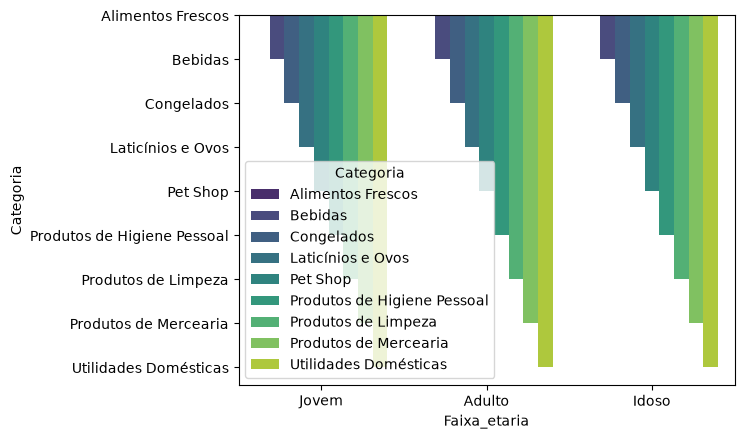

In [259]:
sns.barplot(data=idade_categoria, x="Faixa_etaria", y= "Categoria", hue='Categoria', palette="viridis")

6. Qual a distribuição das vendas ao longo dos dias da semana?


7. Como as vendas mensais se comparam antes e durante a Black Friday?


8. Qual é o ticket médio (valor médio das vendas) por faixa etária e como ele varia entre
diferentes categorias de produto?


9. Comparando a semana da “Black Friday” com a do Natal, qual semana a empresa teve
melhores desempenhos em relação à média de vendas?


10.Qual foi o impacto das promoções (descontos aplicados) nas vendas? Quais produtos
tiveram o maior aumento nas vendas durante as promoções?